,Method,MSE,R-squared
0,Gradient Descent,1.2923,0.0138
1,Normal Equation,1.2923,0.0138


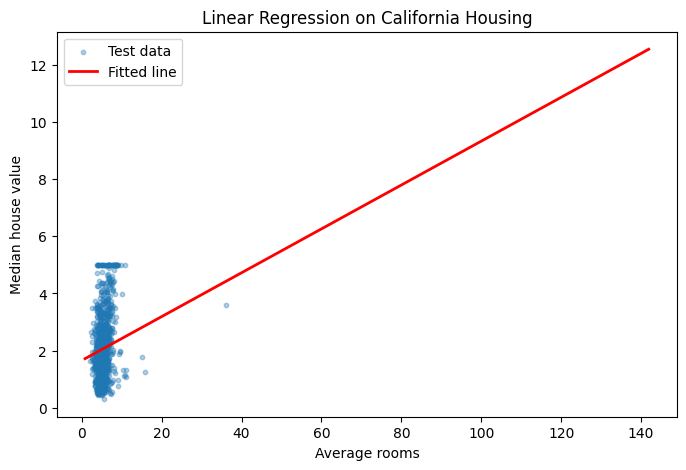

In [1]:
# Experiment 1: Linear Regression on the California Housing Dataset
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Load and preprocess the data.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
housing = fetch_california_housing(as_frame=True, data_home=data_home)
X = housing.frame[["AveRooms"]].to_numpy()
y = housing.target.to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

# Implement linear regression using both gradient descent and the normal equation.
X_train_b = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_b = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]
theta_gd = np.zeros(X_train_b.shape[1])
learning_rate = 0.05
for _ in range(3000):
    gradient = (2 / len(X_train_b)) * X_train_b.T @ (X_train_b @ theta_gd - y_train)
    theta_gd -= learning_rate * gradient
theta_ne = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

# Evaluate the model performance using metrics such as Mean Squared Error (MSE) and R-squared.
predictions = {
    "Gradient Descent": X_test_b @ theta_gd,
    "Normal Equation": X_test_b @ theta_ne,
}
results = pd.DataFrame([
    {
        "Method": name,
        "MSE": mean_squared_error(y_test, prediction),
        "R-squared": r2_score(y_test, prediction),
    }
    for name, prediction in predictions.items()
])
display(results.round(4))

# Visualize the fitted line along with the data points.
x_line = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
x_line_scaled = (x_line - mean) / std
y_line = np.c_[np.ones(len(x_line_scaled)), x_line_scaled] @ theta_ne
plt.figure(figsize=(8, 5))
plt.scatter(X_test[:1000], y_test[:1000], s=10, alpha=0.35, label="Test data")
plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted line")
plt.xlabel("Average rooms")
plt.ylabel("Median house value")
plt.title("Linear Regression on California Housing")
plt.legend()
plt.show()

,Degree,MSE,R-squared
0,1,18.1025,0.6633
1,2,15.1074,0.7190
2,3,14.9436,0.7221


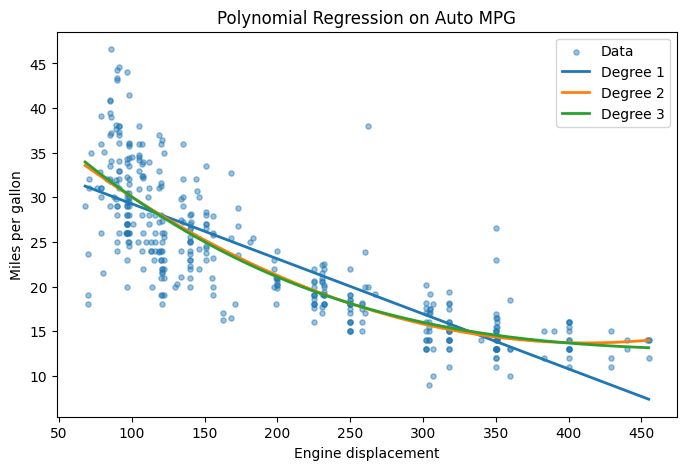

In [2]:
# Experiment 2: Polynomial Regression on the Auto MPG Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Load and preprocess the dataset.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columns = [
    "mpg", "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin", "car_name"
]
auto = pd.read_csv(url, sep=r"\s+", names=columns, na_values="?")
auto = auto.dropna(subset=["displacement", "mpg"])
X = auto[["displacement"]]
y = auto["mpg"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Implement polynomial regression of varying degrees.
models = {}
rows = []
for degree in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    models[degree] = model
    rows.append({
        "Degree": degree,
        "MSE": mean_squared_error(y_test, prediction),
        "R-squared": r2_score(y_test, prediction),
    })

# Compare the polynomial regression models with linear regression using metrics such as MSE and R-squared.
display(pd.DataFrame(rows).round(4))

# Visualize the polynomial fit.
x_line = pd.DataFrame({"displacement": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})
plt.figure(figsize=(8, 5))
plt.scatter(X, y, s=14, alpha=0.45, label="Data")
for degree, model in models.items():
    plt.plot(x_line, model.predict(x_line), linewidth=2, label=f"Degree {degree}")
plt.xlabel("Engine displacement")
plt.ylabel("Miles per gallon")
plt.title("Polynomial Regression on Auto MPG")
plt.legend()
plt.show()

In [3]:
# Experiment 3: Ridge and Lasso Regression on the Diabetes Dataset
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Load and preprocess the dataset.
X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Implement Ridge and Lasso regression.
linear = make_pipeline(StandardScaler(), LinearRegression())
ridge = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
)
lasso = GridSearchCV(
    make_pipeline(StandardScaler(), Lasso(max_iter=20000)),
    {"lasso__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
)

# Tune hyperparameters using cross-validation.
models = {"Linear Regression": linear, "Ridge": ridge, "Lasso": lasso}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    best_alpha = model.best_params_[next(iter(model.best_params_))] if hasattr(model, "best_params_") else None
    rows.append({
        "Model": name,
        "Best alpha": best_alpha,
        "MSE": mean_squared_error(y_test, prediction),
        "R-squared": r2_score(y_test, prediction),
    })

# Compare performance metrics (MSE, R-squared) with standard linear regression.
display(pd.DataFrame(rows).round(4))

,Model,Best alpha,MSE,R-squared
0,Linear Regression,NaN,2900.1936,0.4526
1,Ridge,10.0,2875.7787,0.4572
2,Lasso,1.0,2824.5681,0.4669


In [4]:
# Experiment 4: Logistic Regression Using MLE and MAP
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

# Load and preprocess the dataset.
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Implement logistic regression with MLE.
models = {
    "MLE": LogisticRegression(penalty=None, max_iter=5000, random_state=42),
    "MAP with L1 prior": LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=5000, random_state=42),
    "MAP with L2 prior": LogisticRegression(penalty="l2", C=1.0, max_iter=5000, random_state=42),
}

# Apply MAP estimation with different regularization priors (L1 and L2 regularization).
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)
    rows.append({
        "Method": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Log loss": log_loss(y_test, probability),
        "L1 coefficient norm": np.abs(model.coef_).sum(),
        "L2 coefficient norm": np.linalg.norm(model.coef_),
        "Non-zero coefficients": np.count_nonzero(np.abs(model.coef_) > 1e-6),
    })

# Compare the performance and parameter estimates with MLE and MAP.
display(pd.DataFrame(rows).round(4))
print("MLE has no coefficient penalty, L1 can set coefficients to zero, and L2 shrinks coefficients toward zero.")

,Method,Accuracy,Log loss,L1 coefficient norm,L2 coefficient norm,Non-zero coefficients
0,MLE,0.9211,2.7974,2729.3958,681.0459,30
1,MAP with L1 prior,0.9912,0.0752,13.9612,5.0325,16
2,MAP with L2 prior,0.9825,0.0777,17.2501,3.5889,30


MLE has no coefficient penalty, L1 can set coefficients to zero, and L2 shrinks coefficients toward zero.


In [5]:
# Experiment 5: MLE and MAP for a Multinomial Distribution
import os
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer

# Load and preprocess the dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
news = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"), data_home=data_home)
vectorizer = CountVectorizer(stop_words="english", max_features=5000)
X = vectorizer.fit_transform(news.data)
words = np.array(vectorizer.get_feature_names_out())

# Implement MLE for multinomial distribution parameter estimation.
class_counts = np.vstack([np.asarray(X[news.target == i].sum(axis=0)).ravel() for i in range(len(news.target_names))])

# Apply MAP estimation with various priors (e.g., Dirichlet priors).
estimates = {}
for alpha in [0.0, 0.1, 1.0]:
    estimates[alpha] = (class_counts + alpha) / (
        class_counts.sum(axis=1, keepdims=True) + alpha * class_counts.shape[1]
    )

# Compare results and evaluate the effect of different priors.
rows = []
for alpha, probabilities in estimates.items():
    safe = np.where(probabilities > 0, probabilities, 1)
    entropy = -(probabilities * np.log(safe)).sum(axis=1).mean()
    rows.append({
        "Estimate": "MLE" if alpha == 0 else f"MAP, Dirichlet alpha={alpha}",
        "Mean zero probabilities per class": (probabilities == 0).sum(axis=1).mean(),
        "Mean entropy": entropy,
    })
display(pd.DataFrame(rows).round(4))
class_index = 0
top_rows = []
for alpha, probabilities in estimates.items():
    top = np.argsort(probabilities[class_index])[-10:][::-1]
    top_rows.append({
        "Estimate": "MLE" if alpha == 0 else f"MAP alpha={alpha}",
        "Class": news.target_names[class_index],
        "Top words": ", ".join(words[top]),
    })
display(pd.DataFrame(top_rows))
print("Dirichlet priors remove zero probabilities and increase smoothing; a larger alpha makes the estimated distribution more uniform.")

,Estimate,Mean zero probabilities per class,Mean entropy
0,MLE,1383.0,7.1333
1,"MAP, Dirichlet alpha=0.1",0.0,7.1613
2,"MAP, Dirichlet alpha=1.0",0.0,7.3377


,Estimate,Class,Top words
0,MLE,alt.atheism,"god, people, don, think, just, does, say, athe..."
1,MAP alpha=0.1,alt.atheism,"god, people, don, think, just, does, say, athe..."
2,MAP alpha=1.0,alt.atheism,"god, people, don, think, just, does, say, athe..."


Dirichlet priors remove zero probabilities and increase smoothing; a larger alpha makes the estimated distribution more uniform.


In [6]:
# Experiment 6: Logistic Regression on the Pima Indians Diabetes Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load and preprocess the Pima Indians Diabetes dataset.
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
data = pd.read_csv(url)
X = data.drop(columns="Outcome")
y = data["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Implement logistic regression for binary classification.
models = {
    "Without feature scaling": LogisticRegression(max_iter=5000, random_state=42),
    "With feature scaling": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, random_state=42)
    ),
}

# Evaluate model performance with and without feature scaling.
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1-score": f1_score(y_test, prediction),
    })

# Analyze metrics such as accuracy, precision, recall, and F1-score.
display(pd.DataFrame(rows).round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Without feature scaling,0.7143,0.6087,0.5185,0.56
1,With feature scaling,0.7143,0.6087,0.5185,0.56


In [7]:
# Experiment 7: Naive Bayes Classification on the 20 Newsgroups Dataset
import os
import pandas as pd
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, f1_score

# Load and preprocess the 20 Newsgroups dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"), data_home=data_home)
test = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"), data_home=data_home)
vectorizer = CountVectorizer(stop_words="english", max_features=10000)
X_train = vectorizer.fit_transform(train.data)
X_test = vectorizer.transform(test.data)

# Implement Multinomial Naive Bayes and Bernoulli Naive Bayes classifiers.
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Bernoulli Naive Bayes": BernoulliNB(),
}

# Evaluate and compare the performance of both models using metrics such as accuracy and F1-score.
rows = []
for name, model in models.items():
    model.fit(X_train, train.target)
    prediction = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(test.target, prediction),
        "Macro F1-score": f1_score(test.target, prediction, average="macro"),
    })
results = pd.DataFrame(rows)
display(results.round(4))

# Discuss the strengths and weaknesses of each Naive Bayes variant for text classification.
print("Best accuracy:", results.loc[results["Accuracy"].idxmax(), "Model"])
print("Best macro F1-score:", results.loc[results["Macro F1-score"].idxmax(), "Model"])
print("Multinomial Naive Bayes uses word frequencies, while Bernoulli Naive Bayes uses word presence and may lose useful count information.")

,Model,Accuracy,Macro F1-score
0,Multinomial Naive Bayes,0.6279,0.6021
1,Bernoulli Naive Bayes,0.5035,0.4985


Best accuracy: Multinomial Naive Bayes
Best macro F1-score: Multinomial Naive Bayes
Multinomial Naive Bayes uses word frequencies, while Bernoulli Naive Bayes uses word presence and may lose useful count information.


In [8]:
# Experiment 8: K-Nearest Neighbors on the Fashion MNIST Dataset
import os
import time
import gzip
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load and preprocess the Fashion MNIST dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
data_home = Path(data_home) / "fashion_mnist"
data_home.mkdir(parents=True, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in files.values():
    path = data_home / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)
with gzip.open(data_home / files["train_images"], "rb") as file:
    train_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["train_labels"], "rb") as file:
    train_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
with gzip.open(data_home / files["test_images"], "rb") as file:
    test_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["test_labels"], "rb") as file:
    test_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
X = np.vstack([train_images, test_images]).astype("float32") / 255.0
y = np.concatenate([train_labels, test_labels]).astype("int64")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=10000, test_size=2000, stratify=y, random_state=42
)

# Implement KNN for multi-class classification.
rows = []
for k in [3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    elapsed = time.perf_counter() - start
    rows.append({"K": k, "Accuracy": accuracy_score(y_test, prediction), "Run time (seconds)": elapsed})

# Experiment with different values of K and evaluate performance.
results = pd.DataFrame(rows)
display(results.round(4))

# Discuss the impact of different K values on model accuracy and computational efficiency.
print("Highest accuracy at K =", int(results.loc[results["Accuracy"].idxmax(), "K"]))
print("Shortest run time at K =", int(results.loc[results["Run time (seconds)"].idxmin(), "K"]))
print("A larger K gives a smoother decision boundary but requires more neighbor comparisons during prediction.")

,K,Accuracy,Run time (seconds)
0,3,0.8260,0.2372
1,5,0.8265,0.1951
2,7,0.8275,0.1865


Highest accuracy at K = 7
Shortest run time at K = 7
A larger K gives a smoother decision boundary but requires more neighbor comparisons during prediction.


In [ ]:
# Experiment 9: ID3 Decision Tree on the Online Retail Dataset
import os
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# Load and preprocess the Online Retail dataset.
data_home = Path("/content/ml_data" if os.path.exists("/content") else "ml_data")
data_home.mkdir(parents=True, exist_ok=True)
zip_path = data_home / "online_retail.zip"
xlsx_path = data_home / "Online Retail.xlsx"
if not xlsx_path.exists():
    if not zip_path.exists():
        urlretrieve("https://archive.ics.uci.edu/static/public/352/online+retail.zip", zip_path)
    with ZipFile(zip_path) as archive:
        archive.extract("Online Retail.xlsx", data_home)
retail = pd.read_excel(xlsx_path)
retail = retail.dropna(subset=["CustomerID"])
retail = retail[(retail["Quantity"] > 0) & (retail["UnitPrice"] > 0)]
retail["TotalPrice"] = retail["Quantity"] * retail["UnitPrice"]
reference_date = retail["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = retail.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda values: (reference_date - values.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
rfm["HighValue"] = (rfm["Monetary"] >= rfm["Monetary"].median()).astype(int)
X = rfm[["Recency", "Frequency"]]
y = rfm["HighValue"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Implement Decision Tree using the ID3 algorithm.
model = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
model.fit(X_train, y_train)
prediction = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, prediction), 4))
print(classification_report(y_test, prediction, target_names=["Regular Value", "High Value"]))

# Visualize the decision tree and analyze feature importance.
plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=X.columns, class_names=["Regular Value", "High Value"], filled=True, rounded=True)
plt.title("ID3 Decision Tree for Online Retail Customers")
plt.show()
display(pd.DataFrame({"Feature": X.columns, "Importance": model.feature_importances_}).sort_values("Importance", ascending=False).round(4))

# Discuss how the tree structure helps in understanding customer behavior.
print("The tree shows how recency and purchase frequency separate regular-value and high-value customers.")

In [ ]:
# Experiment 10: Logistic Regression vs. Decision Trees
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load and preprocess the Adult Income dataset.
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income"
]
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"
adult_train = pd.read_csv(train_url, names=columns, skipinitialspace=True, na_values="?")
adult_test = pd.read_csv(test_url, names=columns, skiprows=1, skipinitialspace=True, na_values="?")
adult = pd.concat([adult_train, adult_test], ignore_index=True)
adult["income"] = adult["income"].str.replace(".", "", regex=False)
X = adult.drop(columns="income")
y = adult["income"].eq(">50K").astype(int)
X, _, y, _ = train_test_split(X, y, train_size=15000, stratify=y, random_state=42)
numeric = X.select_dtypes(include=np.number).columns.tolist()
categorical = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Implement both Logistic Regression and Decision Trees.
models = {
    "Logistic Regression": Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(max_iter=2000, random_state=42))]),
    "Decision Tree": Pipeline([("preprocess", preprocessor), ("model", DecisionTreeClassifier(max_depth=8, random_state=42))]),
}

# Compare the models based on metrics such as accuracy, precision, recall, and F1-score.
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1-score": f1_score(y_test, prediction),
    })
display(pd.DataFrame(rows).round(4))

# Discuss the interpretability of both models and their suitability for the dataset.
feature_names = models["Logistic Regression"].named_steps["preprocess"].get_feature_names_out()
logistic_values = np.abs(models["Logistic Regression"].named_steps["model"].coef_[0])
tree_values = models["Decision Tree"].named_steps["model"].feature_importances_
importance = pd.DataFrame({
    "Feature": feature_names,
    "Logistic coefficient magnitude": logistic_values,
    "Decision tree importance": tree_values,
})
display(importance.sort_values("Logistic coefficient magnitude", ascending=False).head(10).round(4))
display(importance.sort_values("Decision tree importance", ascending=False).head(10).round(4))
print("Logistic regression gives global coefficient effects and suits approximately linear relationships.")
print("A decision tree gives readable rules and captures nonlinear interactions, but a deep tree can overfit.")

In [ ]:
# Experiment 11: Linear SVM on the Iris Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Load and preprocess the Iris dataset.
iris = load_iris()
X = iris.data[:, [2, 3]]
y = (iris.target != 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Implement a Linear SVM for binary classification (e.g., classify Setosa vs. Non-Setosa).
model = SVC(kernel="linear", C=1.0)
model.fit(X_train_scaled, y_train)
prediction = model.predict(X_test_scaled)
print("Accuracy:", round(accuracy_score(y_test, prediction), 4))
print(classification_report(y_test, prediction, target_names=["Setosa", "Non-Setosa"]))

# Visualize the decision boundary and margin.
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
decision = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contour(xx, yy, decision, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train, cmap="coolwarm", edgecolor="black")
plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=120, facecolors="none", edgecolors="green", label="Support vectors")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Linear SVM Decision Boundary and Margin")
plt.legend()
plt.show()

# Discuss the concept of the margin and how it influences classification.
print("The margin is the distance between the dashed lines. The support vectors determine its position and width.")

In [ ]:
# Experiment 12: Comparing SVM Kernels on Fashion MNIST
import os
import time
import gzip
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load and preprocess the Fashion MNIST dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
data_home = Path(data_home) / "fashion_mnist"
data_home.mkdir(parents=True, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in files.values():
    path = data_home / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)
with gzip.open(data_home / files["train_images"], "rb") as file:
    train_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["train_labels"], "rb") as file:
    train_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
with gzip.open(data_home / files["test_images"], "rb") as file:
    test_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["test_labels"], "rb") as file:
    test_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
X = np.vstack([train_images, test_images]).astype("float32") / 255.0
y = np.concatenate([train_labels, test_labels]).astype("int64")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=5000, test_size=1000, stratify=y, random_state=42
)

# Implement SVM with linear, polynomial, and RBF kernels.
rows = []
for kernel in ["linear", "poly", "rbf"]:
    model = SVC(kernel=kernel, C=1.0, gamma="scale")
    start = time.perf_counter()
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    elapsed = time.perf_counter() - start
    rows.append({"Kernel": kernel, "Accuracy": accuracy_score(y_test, prediction), "Run time (seconds)": elapsed})

# Compare the classification performance for each kernel.
results = pd.DataFrame(rows)
display(results.round(4))

# Discuss the strengths and weaknesses of each kernel type.
print("Highest accuracy:", results.loc[results["Accuracy"].idxmax(), "Kernel"])
print("Shortest run time:", results.loc[results["Run time (seconds)"].idxmin(), "Kernel"])
print("The linear kernel is simple and fast, the polynomial kernel models feature interactions, and the RBF kernel handles nonlinear boundaries but requires more computation.")

In [ ]:
# Experiment 13: Multilayer Feed-Forward Network on the Wine Quality Dataset
from warnings import filterwarnings
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

filterwarnings("ignore", category=ConvergenceWarning)

# Load and preprocess the Wine Quality dataset.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url, sep=";")
X = wine.drop(columns="quality")
y = wine["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Design and implement an MLP with varying architectures (different hidden layers and neurons).
architectures = [(50,), (100,), (64, 32)]
rows = []
for architecture in architectures:
    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=architecture, max_iter=500, early_stopping=True, random_state=42),
    )

    # Train and evaluate the network.
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "Hidden layers": str(architecture),
        "Accuracy": accuracy_score(y_test, prediction),
        "Macro F1-score": f1_score(y_test, prediction, average="macro"),
        "Iterations": model.named_steps["mlpclassifier"].n_iter_,
    })

# Discuss the impact of architecture choices on performance.
results = pd.DataFrame(rows)
display(results.round(4))
best = results.loc[results["Accuracy"].idxmax()]
print("Best architecture:", best["Hidden layers"], "with accuracy", round(best["Accuracy"], 4))
print("Adding more neurons or layers increases model complexity but does not always improve test performance.")

In [ ]:
# Experiment 14: Comparing Neural-Network Activation Functions
import os
import time
import gzip
from pathlib import Path
from urllib.request import urlretrieve
from warnings import filterwarnings
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

filterwarnings("ignore", category=ConvergenceWarning)

# Load and preprocess the MNIST dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
data_home = Path(data_home) / "mnist"
data_home.mkdir(parents=True, exist_ok=True)
base_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"
files = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in files.values():
    path = data_home / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)
with gzip.open(data_home / files["train_images"], "rb") as file:
    train_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["train_labels"], "rb") as file:
    train_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
with gzip.open(data_home / files["test_images"], "rb") as file:
    test_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["test_labels"], "rb") as file:
    test_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
X = np.vstack([train_images, test_images]).astype("float32") / 255.0
y = np.concatenate([train_labels, test_labels]).astype("int64")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=10000, test_size=2000, stratify=y, random_state=42
)

# Implement neural networks using Sigmoid, ReLU, and Tanh activation functions.
rows = []
for activation in ["logistic", "relu", "tanh"]:
    model = MLPClassifier(
        hidden_layer_sizes=(64,), activation=activation, max_iter=30,
        early_stopping=True, random_state=42
    )

    # Train and evaluate each network.
    start = time.perf_counter()
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    elapsed = time.perf_counter() - start
    rows.append({
        "Activation": "sigmoid" if activation == "logistic" else activation,
        "Accuracy": accuracy_score(y_test, prediction),
        "Training time (seconds)": elapsed,
        "Iterations": model.n_iter_,
    })

# Compare training times, convergence, and classification accuracy.
display(pd.DataFrame(rows).round(4))

In [ ]:
# Experiment 15: Neural-Network Hyperparameter Tuning
import os
import gzip
from pathlib import Path
from urllib.request import urlretrieve
from warnings import filterwarnings
from itertools import product
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

filterwarnings("ignore", category=ConvergenceWarning)

# Load and preprocess the Fashion MNIST dataset.
data_home = "/content/ml_data" if os.path.exists("/content") else "ml_data"
data_home = Path(data_home) / "fashion_mnist"
data_home.mkdir(parents=True, exist_ok=True)
base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
files = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in files.values():
    path = data_home / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)
with gzip.open(data_home / files["train_images"], "rb") as file:
    train_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["train_labels"], "rb") as file:
    train_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
with gzip.open(data_home / files["test_images"], "rb") as file:
    test_images = np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 784)
with gzip.open(data_home / files["test_labels"], "rb") as file:
    test_labels = np.frombuffer(file.read(), dtype=np.uint8, offset=8)
X = np.vstack([train_images, test_images]).astype("float32") / 255.0
y = np.concatenate([train_labels, test_labels]).astype("int64")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=8000, test_size=2000, stratify=y, random_state=42
)

# Experiment with different hyperparameters (learning rate, batch size, epochs).
rows = []
for learning_rate, batch_size, epochs in product([0.001, 0.01], [64, 128], [10, 20]):
    model = MLPClassifier(
        hidden_layer_sizes=(64,), learning_rate_init=learning_rate,
        batch_size=batch_size, max_iter=epochs, random_state=42
    )

    # Train and evaluate the network.
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "Learning rate": learning_rate,
        "Batch size": batch_size,
        "Epochs": epochs,
        "Accuracy": accuracy_score(y_test, prediction),
    })

# Discuss how hyperparameter choices affect model performance.
results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False)
display(results.round(4))
best = results.iloc[0]
print("Best combination: learning rate =", best["Learning rate"], ", batch size =", int(best["Batch size"]), ", epochs =", int(best["Epochs"]))
print("Learning rate controls update size, batch size controls each update, and epochs control the number of training passes.")

In [ ]:
# Experiment 16: Hierarchical and Partitional Clustering
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load and preprocess the Mall Customers dataset.
url = "https://raw.githubusercontent.com/DataThinkers/Datasets/main/DS/Mall_Customers.csv"
customers = pd.read_csv(url)
X = customers[["Annual Income (k$)", "Spending Score (1-100)"]]
X_scaled = StandardScaler().fit_transform(X)

# Apply both hierarchical (agglomerative) and K-means clustering.
kmeans = KMeans(n_clusters=5, n_init=20, random_state=42)
hierarchical = AgglomerativeClustering(n_clusters=5)
kmeans_labels = kmeans.fit_predict(X_scaled)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Compare results using metrics such as inertia, silhouette score, and clustering visualization.
results = pd.DataFrame([
    {"Method": "K-means", "Inertia": kmeans.inertia_, "Silhouette score": silhouette_score(X_scaled, kmeans_labels)},
    {"Method": "Agglomerative", "Inertia": None, "Silhouette score": silhouette_score(X_scaled, hierarchical_labels)},
])
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=kmeans_labels, cmap="tab10")
axes[0].set_title("K-means Clustering")
axes[1].scatter(X.iloc[:, 0], X.iloc[:, 1], c=hierarchical_labels, cmap="tab10")
axes[1].set_title("Agglomerative Clustering")
for axis in axes:
    axis.set_xlabel("Annual Income (k$)")
    axis.set_ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

# Discuss the advantages and disadvantages of each clustering method.
print("K-means is fast and provides inertia, but it assumes centroid-shaped clusters and requires K in advance.")
print("Agglomerative clustering shows a hierarchy and does not use centroids, but it is more expensive and has no inertia value.")

In [ ]:
# Experiment 17: K-Means Clustering on the Digits Dataset
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load and preprocess the Digits dataset.
digits = load_digits()
X = StandardScaler().fit_transform(digits.data)

# Implement K-means clustering with various numbers of clusters.
rows = []
for k in [8, 10, 12]:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X)

    # Evaluate clustering performance using inertia and silhouette score.
    rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette score": silhouette_score(X, labels),
    })
results = pd.DataFrame(rows)
display(results.round(4))

# Analyze the impact of the number of clusters on clustering quality.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results["K"], results["Inertia"], marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")
axes[1].plot(results["K"], results["Silhouette score"], marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()
print("Lowest inertia at K =", int(results.loc[results["Inertia"].idxmin(), "K"]))
print("Highest silhouette score at K =", int(results.loc[results["Silhouette score"].idxmax(), "K"]))
print("Inertia decreases as K increases, while the silhouette score measures how well separated the clusters remain.")

In [ ]:
# Experiment 18: Bootstrapping and Cross-Validation
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils import resample

# Load and preprocess the Iris dataset.
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Implement bootstrapping to generate multiple samples and evaluate the model.
bootstrap_accuracy = []
bootstrap_f1 = []
for seed in range(100):
    X_sample, y_sample = resample(X_train, y_train, replace=True, random_state=seed, stratify=y_train)
    model = DecisionTreeClassifier(random_state=seed)
    model.fit(X_sample, y_sample)
    prediction = model.predict(X_test)
    bootstrap_accuracy.append(accuracy_score(y_test, prediction))
    bootstrap_f1.append(f1_score(y_test, prediction, average="weighted"))

# Implement k-fold cross-validation and evaluate the model.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_validate(
    DecisionTreeClassifier(random_state=42), X, y, cv=cv,
    scoring={"accuracy": "accuracy", "f1": "f1_weighted"}
)

# Compare the performance metrics and discuss the pros and cons of each resampling method.
results = pd.DataFrame([
    {"Method": "Bootstrapping", "Mean accuracy": np.mean(bootstrap_accuracy), "Accuracy standard deviation": np.std(bootstrap_accuracy), "Mean F1-score": np.mean(bootstrap_f1)},
    {"Method": "5-fold cross-validation", "Mean accuracy": cv_scores["test_accuracy"].mean(), "Accuracy standard deviation": cv_scores["test_accuracy"].std(), "Mean F1-score": cv_scores["test_f1"].mean()},
])
display(results.round(4))
print("Bootstrapping estimates variation through repeated sampling, but duplicated observations leave some data unused in each sample.")
print("Cross-validation uses every observation for validation across folds, but it requires repeated model training.")

In [ ]:
# Experiment 19: Bagging and Boosting on the Titanic Dataset
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load and preprocess the Titanic dataset.
titanic = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = titanic[features]
y = titanic["survived"].astype(int)
numeric = ["pclass", "age", "sibsp", "parch", "fare"]
categorical = ["sex", "embarked"]
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Implement bagging using a base classifier (e.g., decision tree) and evaluate performance.
# Implement boosting using a boosting algorithm (e.g., AdaBoost) and evaluate performance.
models = {
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=100, random_state=42),
    "Boosting": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=42), n_estimators=100, learning_rate=0.5, random_state=42),
}
rows = []
for name, estimator in models.items():
    model = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        "Method": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1-score": f1_score(y_test, prediction),
    })

# Compare performance metrics and discuss the strengths and weaknesses of each method.
display(pd.DataFrame(rows).round(4))
print("Bagging reduces variance and is less sensitive to noise, but the ensemble is less interpretable than one tree.")
print("Boosting reduces bias by focusing on earlier errors, but it can be more sensitive to noisy observations.")

In [ ]:
# Experiment 20: Bias-Variance Tradeoff
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Load and preprocess the Boston Housing dataset.
url = "https://lib.stat.cmu.edu/datasets/boston"
raw = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)
values = np.hstack([raw.values[::2, :], raw.values[1::2, :2]])
target = raw.values[1::2, 2]
columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"]
X = pd.DataFrame(values, columns=columns)[["LSTAT"]]
y = pd.Series(target, name="MEDV")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Implement polynomial regression with varying degrees.
rows = []
for degree in [1, 2, 3, 4, 5, 7, 9, 11, 13, 15]:
    model = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    rows.append({
        "Degree": degree,
        "Training MSE": mean_squared_error(y_train, train_prediction),
        "Validation MSE": mean_squared_error(y_test, test_prediction),
        "Validation R-squared": r2_score(y_test, test_prediction),
    })
results = pd.DataFrame(rows)
display(results.round(4))

# Plot training and validation errors for each degree.
plt.figure(figsize=(8, 5))
plt.plot(results["Degree"], results["Training MSE"], marker="o", label="Training error")
plt.plot(results["Degree"], results["Validation MSE"], marker="o", label="Validation error")
plt.xlabel("Polynomial degree")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Tradeoff on Boston Housing")
plt.legend()
plt.show()

# Discuss the bias-variance tradeoff and its impact on model performance.
print("Lowest validation error at degree", int(results.loc[results["Validation MSE"].idxmin(), "Degree"]))
print("Low-degree models can underfit with high bias, while very high-degree models can overfit with high variance.")